In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


In [8]:
def load_relational_data():
    print("Loading relational tables...")
    df_patients = pd.read_csv("D:/Data Analytics/PROJECT 03--Healthcare & disease Prediction/patients.csv")
    df_med_records = pd.read_csv("D:/Data Analytics/PROJECT 03--Healthcare & disease Prediction/medical_records.csv")
    df_tests = pd.read_csv("D:/Data Analytics/PROJECT 03--Healthcare & disease Prediction/test_results.csv")
    df_diag = pd.read_csv("D:/Data Analytics/PROJECT 03--Healthcare & disease Prediction/diagnoses.csv")

    # Merge on Patient_ID
    df = (
        df_patients
        .merge(df_med_records, on="Patient_ID")
        .merge(df_tests, on="Patient_ID")
        .merge(df_diag, on="Patient_ID")
    )

    # Drop surrogate database IDs
    df = df.drop(columns=["Record_ID", "Test_ID", "Diagnosis_ID", "Patient_ID"], errors="ignore")
    print(f"Data joined successfully! Merged shape: {df.shape}")
    return df

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [11]:
def load_relational_data():
    base_path = "D:/Data Analytics/PROJECT 03--Healthcare & disease Prediction"
    
    print("Loading 4 relational tables...")
    df_patients = pd.read_csv(f"{base_path}/patients.csv")
    df_med_records = pd.read_csv(f"{base_path}/medical_records.csv")
    df_tests = pd.read_csv(f"{base_path}/test_results.csv")
    df_diag = pd.read_csv(f"{base_path}/diagnoses.csv")

    # Relational merge on Patient_ID
    df = (
        df_patients
        .merge(df_med_records, on="Patient_ID")
        .merge(df_tests, on="Patient_ID")
        .merge(df_diag, on="Patient_ID")
    )

    # Retain a copy with IDs for reference if needed, but remove surrogate keys for modeling
    df_clean = df.drop(columns=["Record_ID", "Test_ID", "Diagnosis_ID", "Patient_ID"], errors="ignore")
    print(f"Data merged successfully! Shape: {df_clean.shape}")
    return df_clean

df_raw = load_relational_data()
df_raw.head()

Loading 4 relational tables...
Data merged successfully! Shape: (10000, 10)


,Age,Gender,Smoking,Diabetes,ChestPainType,RestingBP,Cholesterol,FastingBS,MaxHR,HeartDisease
0,78,Male,0,1,Non-anginal Pain,117,367,1,188,1
1,73,Male,1,0,Asymptomatic,122,166,0,201,0
2,46,Male,1,1,Asymptomatic,108,370,0,162,1
3,46,Male,1,0,Non-anginal Pain,96,341,1,91,1
4,49,Male,0,0,Asymptomatic,166,247,0,84,1


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            10000 non-null  int64
 1   Gender         10000 non-null  str  
 2   Smoking        10000 non-null  int64
 3   Diabetes       10000 non-null  int64
 4   ChestPainType  10000 non-null  str  
 5   RestingBP      10000 non-null  int64
 6   Cholesterol    10000 non-null  int64
 7   FastingBS      10000 non-null  int64
 8   MaxHR          10000 non-null  int64
 9   HeartDisease   10000 non-null  int64
dtypes: int64(8), str(2)
memory usage: 969.5 KB
None

--- Missing Value Count ---
Age              0
Gender           0
Smoking          0
Diabetes         0
ChestPainType    0
RestingBP        0
Cholesterol      0
FastingBS        0
MaxHR            0
HeartDisease     0
dtype: int64

--- Target Variable Distribution ---
HeartDisease
Heart Disease    0.7639
No Disease 

C:\Users\mdmob\AppData\Local\Temp\ipykernel_25712\2740405563.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, x='HeartDisease', palette='Set2', ax=axes[0])
C:\Users\mdmob\AppData\Local\Temp\ipykernel_25712\2740405563.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['No Disease (0)', 'Disease (1)'])


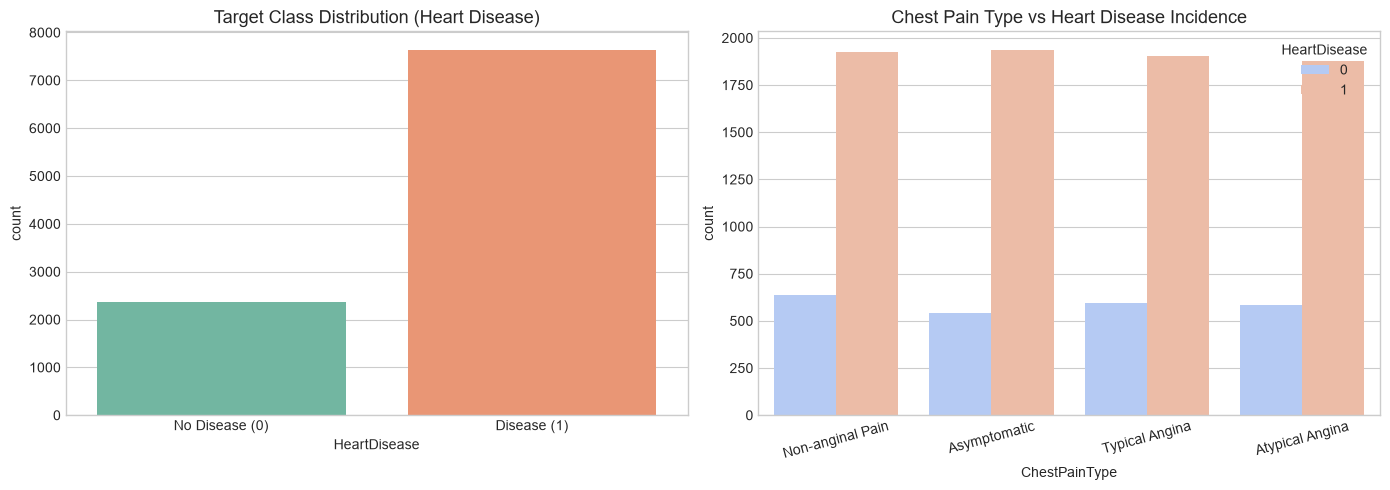

In [12]:
print("--- Dataset Information ---")
print(df_raw.info())

print("\n--- Missing Value Count ---")
print(df_raw.isnull().sum())

print("\n--- Target Variable Distribution ---")
print(df_raw['HeartDisease'].value_counts(normalize=True).rename({0: 'No Disease', 1: 'Heart Disease'}))

# Visualizing target distribution & Chest Pain types
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_raw, x='HeartDisease', palette='Set2', ax=axes[0])
axes[0].set_title('Target Class Distribution (Heart Disease)', fontsize=13)
axes[0].set_xticklabels(['No Disease (0)', 'Disease (1)'])

sns.countplot(data=df_raw, x='ChestPainType', hue='HeartDisease', palette='coolwarm', ax=axes[1])
axes[1].set_title('Chest Pain Type vs Heart Disease Incidence', fontsize=13)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()